<a href="https://colab.research.google.com/github/magnatapedro/classificacao-de-vias/blob/main/Classifica%C3%A7%C3%A3oDeVias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Processo Seletivo Voxar Labs 2026**
**Nome:** Pedro de Souza Leão Pereira Magnata  

**Curso:** Engenharia da Computação - CIn-UFPE   

**Email:** pslpm@cin.ufpe.br

**Telefone:** (81)98310-0206





### **Um pouco mais sobre a Problemática**




O problema consiste em classificar imagens de múltiplas classes utilizando aprendizado supervisionado. Nosso objetivo é construir um modelo capaz de extrair características visuais de uma imagem de entrada e mapeá-las para uma distribuição de probabilidade, permitindo a separação das imagens de vias em três categorias: asfalto, paralelepípedo e off-road.

### **Possíveis entraves na construção e aplicação do modelo**

O principal desafio deste projeto não está na complexidade visual, mas no comportamento de otimização do modelo diante de um conjunto de dados desbalanceado. Nessa situação, observamos que o modelo tende a favorecer a classe majoritária, minimizando o erro global, mas comprometendo o desempenho nas classes minoritárias.

Observamos que redes neurais podem apresentar um comportamento “preguiçoso”, buscando atalhos durante o aprendizado. Por exemplo, se a maioria das imagens de Off-road foi capturada à noite, o modelo pode aprender que ``fundo preto = Off-road``, ignorando a textura da terra. Nesse caso, ele aprende o viés da iluminação, e não o padrão geométrico da via (shortcut learning).

Também identificamos que uma mesma classe pode apresentar aparências completamente distintas. Por exemplo, o asfalto molhado reflete a luz como um espelho, enquanto o asfalto seco possui uma textura opaca. Assim, o modelo precisa ser suficientemente profundo para compreender que ambos pertencem à mesma classe, apesar de apresentarem valores de pixels diferentes.

Em um cenário prático de mobilidade, os erros não possuem o mesmo peso. Um falso positivo de asfalto (classificar uma estrada de terra irregular como um asfalto liso) pode induzir um motorista ou sistema de suspensão a não reduzir a velocidade, causando consequências gravíssimas.

### **Abordagem Adotada**

*Método:* Transfer Learning utilizando um modelo de *arquitetura* ResNet18 pré-treinada no ImageNet.



 *Motivação:* Dado o tempo sugerido (6-10 horas) e a natureza ruidosa das imagens, a ResNet18 oferece bom equilíbrio entre custo computacional e capacidade de extração de características. Em vez de treinar a rede do zero, aproveitamos os filtros  aprendidos em bases como o ImageNet, especializados na detecção de padrões visuais gerais, focando o treinamento apenas na camada final de classificação para as três classes de vias.

*Bibliotecas Principais:* PyTorch (Deep Learning), NumPy (Processamento de Matrizes), Matplotlib (Visualização).

### **Bibliotecas**

In [ ]:
#Bibliotecas
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import os
import matplotlib.pyplot as plt
import gdown
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader

#Verificação de GPU
dispositivo = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Executando em: {dispositivo}")

Executando em: cuda:0


### **Conjunto de Dados**

In [ ]:

print("Baixando e extraindo o dataset...")
#Baixa do Drive e nomeia o arquivo de saída
gdown.download(f'https://drive.google.com/uc?id=1hJvbdlsNXJ4TyhLwAfZ7qhxoIaUKug5t', 'dataset_processed.zip', quiet=False)
#Extrai o .zip
!unzip -q dataset_processed.zip -d /content/dataset
print("Tudo ok!")

Baixando e extraindo o dataset...


Downloading...
From (original): https://drive.google.com/uc?id=1hJvbdlsNXJ4TyhLwAfZ7qhxoIaUKug5t
From (redirected): https://drive.google.com/uc?id=1hJvbdlsNXJ4TyhLwAfZ7qhxoIaUKug5t&confirm=t&uuid=f5db67e7-3d16-4369-b35b-ffc7dbf1515e
To: /content/dataset_processed.zip
100%|██████████| 62.9M/62.9M [00:00<00:00, 64.7MB/s]


Tudo ok!


### **Preparação dos Dados**

In [ ]:


#Caminho da pasta descompactada
data_dir = '/content/dataset/dataset_processed'

#Transformações matemáticas(Data Preprocessing)
data_transforms = {
    'train': transforms.Compose([ #Fila de processamento
        transforms.Resize((224, 224)), #Redimensiona(224x224pixels)
        transforms.ToTensor(),         #Converte a imagem (0-255) para um Tensor PyTorch (0.0-1.0)
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]) #Normalização
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

#Carregando os Datasets
#ImageFolder lê o nome das pastas e cria as labels
image_datasets = {
    x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x])
    for x in ['train', 'test']
}

#DataLoaders
#DataLoaders empacotam lotes(batches) para GPU
dataloaders = {
    x: DataLoader(image_datasets[x], batch_size=32, shuffle=True if x == 'train' else False, num_workers=2)
    for x in ['train', 'test']
}

#Nomes das classes e o tamanho do dataset
class_names = image_datasets['train'].classes
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'test']}

print(f"Classes encontradas: {class_names}")
print(f"Tamanho do treino: {dataset_sizes['train']} imagens")
print(f"Tamanho do teste: {dataset_sizes['test']} imagens")

Classes encontradas: ['asphalt', 'belgian_blocks', 'offroad']
Tamanho do treino: 900 imagens
Tamanho do teste: 300 imagens


**Análise do Código:**

*Padronização Espacial:*

`Resize()`Redimensiona todas as imagens para 224x224 pixels, pois o dataset possui imagens de diferentes dispositivos de captura.

*Vetorização e Normalização:*

``ToTensor()`` converte as matrizes de pixels (0 a 255) em tensores numéricos contínuos entre 0 e 1, para o PyTorch realiza cálculos de gradiente.

``Normalize()`` utiliza a média e o desvio padrão do dataset ImageNet, o que é importante no contexto de Transfer Learning, já que serão empregados os pesos da ResNet18, evitando assim distorções na extração de características (data shift).

*Gerenciamento de Memória e Otimização:*

Em vez de carregar todas as imagens na memória de uma vez (processo lento), utilizamos o `dataLoader` para empacotar os dados em lotes ``batches`` de 32 imagens.

A ativação do ``shuffle=True`` no conjunto de treino é feita para impedir que a rede decore a ordem das imagens ou aprenda vícios de classes agrupadas, promovendo uma boa distribuição durante o backpropagation.

### **Modelo Baseline com Transfer Learning**

In [ ]:

#Carregando a arquitetura ResNet18 com pesos pré-treinados
print("ResNet18")
model_baseline = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

#Congelando os pesos da rede base(Feature Extractor)
for param in model_baseline.parameters():
    param.requires_grad = False

#Substituindo a última camada(Classificador)
#Camada original(fully connected)---> Número de Entradas
num_fitros = model_baseline.fc.in_features
#Nova camada linear que recebe essas entradas e devolve 3 saídas(Classes usadas)
model_baseline.fc = nn.Linear(num_fitros, 3)

#Movendo o modelo para a Placa de Vídeo
dispositivo = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model_baseline = model_baseline.to(dispositivo)

#Função de Perda(Loss)
#Classificação multiclasse
criterion = nn.CrossEntropyLoss()

#Otimizador
#Adam---->Convergência rápida
#APENAS os parâmetros da última camada
optimizer_baseline = optim.Adam(model_baseline.fc.parameters(), lr=0.001)

print("Modelo Baseline construído e enviado:", dispositivo)
print("Preparado para treinar!")

ResNet18
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


Modelo Baseline construído e enviado: cuda:0
Preparado para treinar!


 **Análise do Código:**

A eficiência deste baseline está na técnica de feature extraction. Ao congelarmos as camadas convolucionais pré-treinadas da ResNet18 e treinarmos apenas a nova camada densa fully connected, reaproveitamos extratores visuais já aprendidos, minimizando o custo computacional e estabelecendo um ponto de partida para analisar as métricas do projeto.

**Pontos de Observação:**

Observamos que a função de perda padrão ``CrossEntropyLoss()`` não penaliza os erros de forma ponderada. Em um dataset desbalanceado, isso induz a rede a criar um viés estatístico, priorizando o acerto da classe majoritária, enquanto negligencia as classes minoritárias.

Além disso, o congelamento da rede base impede que o modelo se especialize. Como a ResNet18 foi treinada no ImageNet para identificar objetos genéricos, quando não permitimos a atualização das camadas mais profundas, forçamos o modelo a classificar texturas de pavimentação urbana utilizando representações aprendidas em contextos diferentes da aplicação.


### **Loop Pricipal**

In [ ]:
import time
import copy
#Função de Treinamanto do Modelo
def train_model(model, criterion, optimizer, num_epochs=5):
    since = time.time()

    #Salva os melhores pesos do modelo
    best_model_Weights = copy.deepcopy(model.state_dict())
    best_acuracia = 0.0

    for epoch in range(num_epochs):
        print(f'Época {epoch+1}/{num_epochs}')
        print('-' * 50)

        for phase in ['train', 'test']:
            if phase == 'train':
                model.train()  #Modo de treinamento
            else:
                model.eval()   #Modo de avaliação(congela pesos e desativa dropout)

            perda_total = 0.0
            qtd_predI_corretas = 0

            #Iterando sobre os lotes de imagens(DataLoader)
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(dispositivo)
                labels = labels.to(dispositivo)

                #Zera os gradientes do otimizador
                optimizer.zero_grad()

                #Forward
                #APENAS rastreia o histórico na fase de treino
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    #Backward + Otimização
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                #Estatísticas
                perda_total += loss.item() * inputs.size(0)
                qtd_predI_corretas += torch.sum(preds == labels.data)

            #Calcula a média de erro e acurácia da época
            epoch_loss = perda_total / dataset_sizes[phase]
            epoch_acuracia = qtd_predI_corretas.double() / dataset_sizes[phase]

            print(f'{phase.capitalize()} ---> Loss: {epoch_loss:.4f} | Acurácia: {epoch_acuracia:.4f}')

            #Teste e melhor acurácia---->salva o modelo
            if phase == 'test' and epoch_acuracia > best_acuracia:
                best_acuracia = epoch_acuracia
                best_model_Weights = copy.deepcopy(model.state_dict())
        print()
    time_elapsed = time.time() - since
    print(f'Treinamento concluído em {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Melhor Acurácia de Teste: {best_acuracia:.4f}')

    #Carrega os pesos e retorna o modelo
    model.load_state_dict(best_model_Weights)
    return model
#Treinar 5 épocas
print("Iniciando o treinamento do modelo Baseline")
print()
model_baseline = train_model(model_baseline, criterion, optimizer_baseline, num_epochs=5)

Iniciando o treinamento do modelo Baseline

Época 1/5
--------------------------------------------------
Train ---> Loss: 0.7227 | Acurácia: 0.7522
Test ---> Loss: 0.6393 | Acurácia: 0.7700

Época 2/5
--------------------------------------------------
Train ---> Loss: 0.3546 | Acurácia: 0.8856
Test ---> Loss: 0.5489 | Acurácia: 0.7867

Época 3/5
--------------------------------------------------
Train ---> Loss: 0.2342 | Acurácia: 0.9333
Test ---> Loss: 0.5058 | Acurácia: 0.7967

Época 4/5
--------------------------------------------------
Train ---> Loss: 0.1902 | Acurácia: 0.9522
Test ---> Loss: 0.4584 | Acurácia: 0.8167

Época 5/5
--------------------------------------------------
Train ---> Loss: 0.1638 | Acurácia: 0.9589
Test ---> Loss: 0.4835 | Acurácia: 0.8233

Treinamento concluído em 1m 32s
Melhor Acurácia de Teste: 0.8233


**Análise do Código:**

A função de treinamento segue boas práticas de implementação no framework PyTorch, garantindo eficiência computacional e controle sobre o ciclo de aprendizado do modelo.

*Gerenciamento de Memória:*

Utilizamos o gerenciador de contexto ``with torch.set_grad_enabled(phase == 'train'):`` para desativar a construção do grafo de gradientes durante a fase de teste/avaliação, economizando a memória VRAM da GPU.

*Gestão de estado da Arquitetura:*

Alternamos entre ``model.train() e model.eval()`` para garantir que camadas aleatórias e de normalização se comportem de forma previsível durante a validação, evitando distorções nas métricas de teste.

*Salvamento por Checkpoints:*

Implementamos uma lógica de rastreamento da `best_acuracia` e utilizamos ``copy.deepcopy(model.state_dict())`` para armazenar os melhores pesos do modelo. Essa abordagem atua como um mecanismo de early stopping, reduzindo o risco de overfitting nas últimas épocas e otimizando o tempo de treinamento.

**Pontos de Observação:**

Observamos que a condição utilizada para salvar o melhor modelo baseia-se na acurácia global ``epoch_acuracia > best_acuracia``. No entanto, em datasets desbalanceados, essa métrica pode induzir viés em favor da classe majoritária.



 **Análise dos Resultados:**

Notamos um quadro de overfitting em desenvolvimento. Enquanto a acurácia de treino cresce de forma contínua e acelerada ao longo das épocas (chegando a quase 96%), a acurácia de teste cresce em um ritmo mais contido, atingindo seu pico de 82,33% na Época 5. Esse comportamento evidencia um "gap" importante e crescente entre treino e teste, indicando que o modelo está memorizando os dados de treinamento.

Ao contrário de cenários clássicos de early stopping (interrupção antecipada) baseados na acurácia, não identificamos um momento ideal para interromper o treinamento usando apenas a taxa de acertos no conjunto de validação, visto que ela continuou apresentando ganhos até o final do ciclo de 5 épocas.

Observamos que a loss de treino reduz continuamente, indicando que a rede está se ajustando perfeitamente aos dados de treinamento. No entanto, a loss de teste atinge seu menor valor na Época 4 (0,46) e sofre um leve aumento na Época 5 (0,48).

### **Pipeline de Avaliação do Modelo**

Avaliando o modelo no conjunto de teste...

--- Relatório de Classificação ---
                precision    recall  f1-score   support

       asphalt       0.90      0.90      0.90       218
belgian_blocks       0.80      0.25      0.38        32
       offroad       0.60      0.84      0.70        50

      accuracy                           0.82       300
     macro avg       0.77      0.66      0.66       300
  weighted avg       0.84      0.82      0.81       300



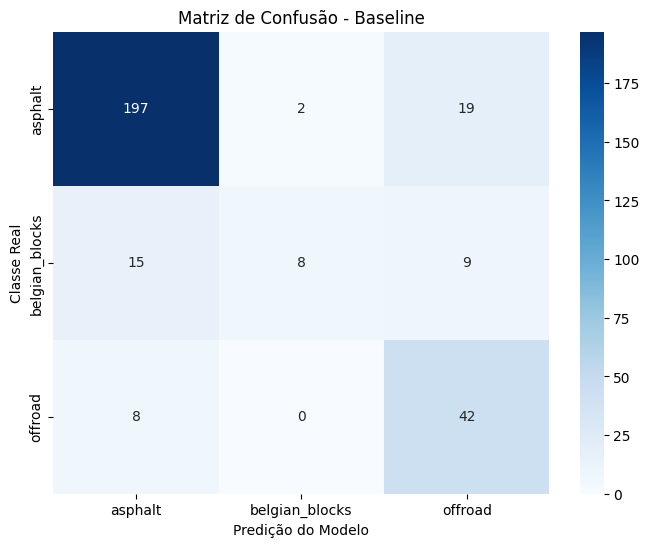

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd

def evaluate_model(model, dataloader):
    model.eval() #Modo de avaliação
    all_predI = [] #Predições
    all_labels = []#Respostas corretas

    #Desativa o cálculo de gradientes para economizar memória
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(dispositivo)
            labels = labels.to(dispositivo)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            #Sklearn
            all_predI.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return all_labels, all_predI

#Avaliação no conjunto de Teste
print("Avaliando o modelo no conjunto de teste...\n")
y_true, y_pred = evaluate_model(model_baseline, dataloaders['test'])

#Relatório de Classificação(F1-Score por classe)
print("--- Relatório de Classificação ---")
print(classification_report(y_true, y_pred, target_names=class_names))

#Matriz de Confusão
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.ylabel('Classe Real')
plt.xlabel('Predição do Modelo')
plt.title('Matriz de Confusão - Baseline')
plt.show()

**Análise do Código:**

Neste código, as predições são geradas pelo modelo na forma de tensores alocados na GPU. Implementamos a transferência explícita desses dados para a memória principal (CPU), seguida da conversão para arrays por meio de ``.cpu().numpy()``. Essa etapa de transformação é essencial, pois permite extrair os dados do ambiente da rede neural e integrá-los de forma eficiente com bibliotecas como o `scikit-learn e o seaborn`, viabilizando métricas consolidadas e a visualização da matriz de confusão.


**Análise dos Resultados:**

Os resultados deste Baseline validam a nossa principal preocupação inicial com os dados: o desbalanceamento das classes dita o comportamento da rede neural.

O modelo atingiu 82% de acurácia global, bom valor para um modelo base, mas a coluna support revela que 218 das 300 imagens de teste pertencem à classe asphalt. Como a rede é majoritariamente exposta ao asfalto, ela foca em acertar essa classe (Recall de 0,90) e, como consequência, a acurácia global acaba inflacionada.

O principal gargalo desta primeira versão está na classe de paralelepípedo (belgian_blocks). O recall foi de apenas 0,25, o que indica que o modelo ignora (ou confunde) 75% dessas vias. Além disso, a precisão para essa classe foi de 0,80, mostrando que o modelo não só realiza poucas previsões para esse tipo de pavimento, como também ainda comete alguns erros (falsos positivos) quando tenta classificá-lo.

A diferença entre o macro avg F1-score (0,66) e o weighted avg F1-score (0,81) ilustra bem o problema. A média ponderada esconde as falhas, pois atribui maior peso à classe com maior número de amostras. Já a média macro, que exige um desempenho equilibrado entre todas as categorias, evidencia que o aprendizado das classes minoritárias está comprometido.


### **Experimento 1: Balanceamento com Pesos por Classe**

**Hipótese:**

Observamos, no modelo baseline, que a rede estava negligenciando a classe minoritária `belgian_blocks` devido à grande diferença na quantidade de imagens no conjunto de treino (655 de asfalto contra apenas 94 de paralelepípedo). Assim, é viável penalizar matematicamente o modelo quando ocorressem erros nas classes com menos dados. Dessa forma, poderíamos forçá-lo a atribuir maior importância aos paralelepípedos, equilibrando o aprendizado e elevando o recall dessa classe.

**Mudanças no Código:**

Calculamos a frequência de cada classe no conjunto de treino e extraímos o seu inverso para gerar "pesos" proporcionais. Como esperado, o peso atribuído à classe `belgian_blocks` foi consideravelmente maior (1,70) em comparação ao asfalto (0,24). Injetamos esses tensores na nossa função de erro através do parâmetro weight da `CrossEntropyLoss`. Então, recriamos a arquitetura ResNet18 do zero (apenas a camada final) para limpar qualquer vício aprendido no experimento anterior e treinamos por 5 épocas.




In [ ]:

print("INICIANDO EXPERIMENTO 1")
print()
#Frequência de cada classe no conjunto de treino
class_counts = [0, 0, 0]
for sample in image_datasets['train'].samples:
    label = sample[1]
    class_counts[label] += 1

print(f"Contagem das classes no treino: {class_counts}")

#Cálculo de pesos (inverso da frequência)
#Ajuste de peso (ajudar a classe minoritária)
weights = 1.0 / torch.tensor(class_counts, dtype=torch.float)
#Normalizando os pesos (controlar o gradiente)
weights = weights / weights.sum() * 3.0
print(f"Pesos calculados para [Asphalt, Belgian, Offroad]: {weights}")

#Pesos--->GPU
weights = weights.to(dispositivo)

#Nova função de perda com os pesos aplicados
criterion_weighted = nn.CrossEntropyLoss(weight=weights)

#Recriando o modelo (resetar os pesos treinados no Baseline)
model_exp1 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model_exp1.parameters():
    param.requires_grad = False
model_exp1.fc = nn.Linear(model_exp1.fc.in_features, 3)
model_exp1 = model_exp1.to(dispositivo)

#Novo otimizador
optimizer_exp1 = optim.Adam(model_exp1.fc.parameters(), lr=0.001)

#Treinando com a função de perda
print("\nTreinando Experimento 1 (com pesos)")
model_exp1 = train_model(model_exp1, criterion_weighted, optimizer_exp1, num_epochs=5)

#Avaliação do experimento
print("\nAvaliando Experimento 1")
y_true_exp1, y_pred_exp1 = evaluate_model(model_exp1, dataloaders['test'])

print("Relatório de Classificação (Experimento 1)")
print(classification_report(y_true_exp1, y_pred_exp1, target_names=class_names))

INICIANDO EXPERIMENTO 1

Contagem das classes no treino: [655, 94, 151]
Pesos calculados para [Asphalt, Belgian, Offroad]: tensor([0.2438, 1.6987, 1.0575])

Treinando Experimento 1 (com pesos)
Época 1/5
--------------------------------------------------
Train ---> Loss: 0.8836 | Acurácia: 0.5422
Test ---> Loss: 0.7741 | Acurácia: 0.7200

Época 2/5
--------------------------------------------------
Train ---> Loss: 0.4489 | Acurácia: 0.8644
Test ---> Loss: 0.6001 | Acurácia: 0.7667

Época 3/5
--------------------------------------------------
Train ---> Loss: 0.3167 | Acurácia: 0.9056
Test ---> Loss: 0.5890 | Acurácia: 0.7567

Época 4/5
--------------------------------------------------
Train ---> Loss: 0.2667 | Acurácia: 0.9144
Test ---> Loss: 0.5384 | Acurácia: 0.7833

Época 5/5
--------------------------------------------------
Train ---> Loss: 0.2317 | Acurácia: 0.9200
Test ---> Loss: 0.5007 | Acurácia: 0.7933

Treinamento concluído em 1m 32s
Melhor Acurácia de Teste: 0.7933

Avalia

**Resultados:**

Observamos que a acurácia global caiu levemente em relação ao Baseline (de 82% para 79%). No entanto, obtivemos um ganho pequeno no nosso objetivo principal: o recall da classe `belgian_blocks` subiu de 0,25 para 0,31. A rede começou a arriscar mais na previsão do paralelepípedo, mas o custo disso foi a queda na sua precisão para essa classe (que caiu de 0,80 para 0,67). Além disso, as métricas por época deixaram evidente um cenário de overfitting, com a acurácia de treino atingindo 92% enquanto o teste estacionou na faixa dos 79%.

**Análise dos Resultados:**

A aplicação de pesos funcionou de forma parcial ao que estava previsto: forçamos a rede a dar mais atenção à classe minoritária, aumentando o recall. A queda na precisão e o forte overfitting indicam que a rede está apenas decorando as 94 imagens de treino do paralelepípedo, em vez de aprender suas características de forma genérica. Concluímos que a manipulação matemática da função de perda ajuda a guiar o foco, mas não cria informação nova.

### **Experimento 2: Aumento de Dados (Data Augmentation)**

**Hipótese:**

No Experimento 1, observamos que a aplicação de pesos na função de perda ajudou a rede a classificar a classe minoritária, mas também gerou um forte overfitting. Nossa hipótese foi a de que, ao introduzirmos data augmentation (distorções visuais aleatórias), poderíamos reduzir essa memorização. Dessa forma, o modelo não veria a mesma imagem exatamente da mesma maneira, o que o forçaria a aprender características mais robustas das vias.

**Mudanças no Código:**

Implementamos um pipeline de transformações apenas para o conjunto de treinamento. Foram aplicados recortes com zoom aleatório `RandomResizedCrop,` espelhamento horizontal `RandomHorizontalFlip` e variações de iluminação e cor `ColorJitter`, simulando diferentes condições de captura, como câmeras distintas e horários do dia. Além disso, ampliamos o ciclo de treinamento de 5 para 7 épocas, proporcionando mais tempo para que a rede assimilasse essas novas variações. Por fim, mantivemos a função de perda balanceada do Experimento 1 e recriamos o modelo base ResNet18, treinando apenas a camada final (fc).

In [ ]:
print("INICIANDO EXPERIMENTO 2")
print()
#Novas Transformações com Data Augmentation (APENAS NO TREINO)
data_transforms_exp2 = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224, scale=(0.8, 1.0)), #zoom
        transforms.RandomHorizontalFlip(), #Espelha horizontalmente
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3), #Simula dias/noites e câmeras diferentes
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)), #Teste NUNCA tem augmentation
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

#Datasets com novas transformações
image_datasets_exp2 = {
    x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms_exp2[x])
    for x in ['train', 'test']
}

dataloaders_exp2 = {
    x: DataLoader(image_datasets_exp2[x], batch_size=32, shuffle=True if x == 'train' else False, num_workers=2)
    for x in ['train', 'test']
}

#Modelo do zero (tirar vícios)
model_exp2 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model_exp2.parameters():
    param.requires_grad = False
model_exp2.fc = nn.Linear(model_exp2.fc.in_features, 3)
model_exp2 = model_exp2.to(dispositivo)

optimizer_exp2 = optim.Adam(model_exp2.fc.parameters(), lr=0.001)

#Treinando (Mesma função de perda balanceada do Experimento 1)
print("\nTreinando Experimento 2 (Augmentation + Pesos)...")
#Treina por 7 épocas (Data Augmentation)---> Modelo ver as variações
model_exp2 = train_model(model_exp2, criterion_weighted, optimizer_exp2, num_epochs=7)

#Avaliando
print("\nAvaliando Experimento 2")
y_true_exp2, y_pred_exp2 = evaluate_model(model_exp2, dataloaders_exp2['test'])

print("Relatório de Classificação (Experimento 2)")
print(classification_report(y_true_exp2, y_pred_exp2, target_names=class_names))

INICIANDO EXPERIMENTO 2


Treinando Experimento 2 (Augmentation + Pesos)...
Época 1/7
--------------------------------------------------
Train ---> Loss: 0.8235 | Acurácia: 0.6200
Test ---> Loss: 0.5964 | Acurácia: 0.8300

Época 2/7
--------------------------------------------------
Train ---> Loss: 0.4093 | Acurácia: 0.8911
Test ---> Loss: 0.5334 | Acurácia: 0.8300

Época 3/7
--------------------------------------------------
Train ---> Loss: 0.3072 | Acurácia: 0.9278
Test ---> Loss: 0.5443 | Acurácia: 0.7867

Época 4/7
--------------------------------------------------
Train ---> Loss: 0.2645 | Acurácia: 0.9044
Test ---> Loss: 0.4970 | Acurácia: 0.8300

Época 5/7
--------------------------------------------------
Train ---> Loss: 0.2643 | Acurácia: 0.9011
Test ---> Loss: 0.4892 | Acurácia: 0.8233

Época 6/7
--------------------------------------------------
Train ---> Loss: 0.2269 | Acurácia: 0.9222
Test ---> Loss: 0.4339 | Acurácia: 0.8300

Época 7/7
--------------------------------

**Resultados:**

A acurácia global subiu levemente para 83%, mas o comportamento nas métricas específicas da nossa classe de foco foi inesperado. O grande baque ocorreu na belgian_blocks: o recall, que havia subido para 0,31 no Experimento 1, despencou para 0,22. A precisão dessa classe ficou em 0,70. A classe offroad também sofreu uma queda no recall, passando para 0,74. Além disso, o overfitting ainda se manteve evidente, com a acurácia de treino chegando a quase 94% na última época, enquanto o teste estagnou na casa dos 83%.

**Análise dos Resultados:**

Interpretamos que o data augmentation aplicado mascarou padrões visuais finos dos quais o modelo dependia. Como treinamos apenas a camada final, mantendo a base convolucional da ResNet18 congelada, a rede não possui capacidade para adaptar seus filtros às transformações introduzidas. Isso impacta de forma severa a classe belgian_blocks, onde a textura sutil das pedras é facilmente ofucada por operações matemáticas como o zoom e o ColorJitter.


### **Experimento 3: Fine-Tuning de Camadas Profundas**

**Hipótese:**

No Experimento 2, observamos que o data augmentation prejudicou a detecção da classe minoritária belgian_blocks. Nossa hipótese foi que isso ocorreu porque os filtros visuais da rede, pré-treinados no ImageNet, estavam congelados e não conseguiam se adaptar às distorções geométricas e de cor aplicadas. Diante disso, vamos testar a técnica de fine-tuning, permitindo a atualização dos filtros convolucionais profundos, com o objetivo de melhorar a extração de padrões específicos das ruas e calçadas do nosso domínio.

**Mudanças no Código:**

Mantivemos o Data Augmentation (Exp 2) e a função de perda balanceada (Exp 1). A grande alteração arquitetural foi o descongelamento do último bloco convolucional da ResNet18 (layer4), permitindo que seus pesos fossem atualizados durante o treino. Para evitar que os pesos pré-treinados dessa camada fossem destruídos rapidamente, implementamos `Differential Learning Rates` (Taxas de Aprendizado Diferenciais): configuramos o otimizador Adam com uma taxa baixa e cuidadosa de (1e-4) para a layer4, e mantivemos a taxa padrão de (1e-3) para a camada final classificadora (fc).

In [ ]:
print("INICIANDO EXPERIMENTO 3: FINE-TUNING")

#Modelo base
model_exp3 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

#Igual ao Baseline
for param in model_exp3.parameters():
    param.requires_grad = False

#Descongelando o ÚLTIMO bloco convolucional
for param in model_exp3.layer4.parameters():
    param.requires_grad = True

#Substituindo a camada final
model_exp3.fc = nn.Linear(model_exp3.fc.in_features, 3)
model_exp3 = model_exp3.to(dispositivo)

#Treina a 'layer4'(ULTIMA CAMADA COVOLUCIONAL) e a 'fc'(CLASSIFICADOR)
#Learning Rate bem menor (1e-4) na layer4
optimizer_exp3 = optim.Adam([
    {'params': model_exp3.layer4.parameters(), 'lr': 1e-4},
    {'params': model_exp3.fc.parameters(), 'lr': 1e-3}
])

#Mantem os pesos do Exp1 e o Augmentation do Exp2
print("\nTreinando Experimento 3 (Fine-tuning + Augmentation + Pesos)")
#Alteração de camadas profundas--->modelo aprende mais rápido
model_exp3 = train_model(model_exp3, criterion_weighted, optimizer_exp3, num_epochs=6)

#Avaliação
print("\nAvaliando Experimento 3")
y_true_exp3, y_pred_exp3 = evaluate_model(model_exp3, dataloaders_exp2['test'])

print("Relatório de Classificação (Experimento 3)")
print(classification_report(y_true_exp3, y_pred_exp3, target_names=class_names))

INICIANDO EXPERIMENTO 3: FINE-TUNING

Treinando Experimento 3 (Fine-tuning + Augmentation + Pesos)
Época 1/6
--------------------------------------------------
Train ---> Loss: 0.2943 | Acurácia: 0.8467
Test ---> Loss: 0.3453 | Acurácia: 0.8833

Época 2/6
--------------------------------------------------
Train ---> Loss: 0.0247 | Acurácia: 0.9944
Test ---> Loss: 0.3075 | Acurácia: 0.9100

Época 3/6
--------------------------------------------------
Train ---> Loss: 0.0147 | Acurácia: 0.9989
Test ---> Loss: 0.2818 | Acurácia: 0.9233

Época 4/6
--------------------------------------------------
Train ---> Loss: 0.0088 | Acurácia: 0.9978
Test ---> Loss: 0.2760 | Acurácia: 0.9200

Época 5/6
--------------------------------------------------
Train ---> Loss: 0.0030 | Acurácia: 1.0000
Test ---> Loss: 0.3171 | Acurácia: 0.9100

Época 6/6
--------------------------------------------------
Train ---> Loss: 0.0022 | Acurácia: 1.0000
Test ---> Loss: 0.2875 | Acurácia: 0.9300

Treinamento concluí

**Resultados:**

Tivemos uma melhora expressiva nas métricas. A acurácia global saltou para 93%. O impacto na nossa classe minoritária belgian_blocks foi notável: o recall subiu significativamente para 0,50, acompanhado de uma precisão altíssima de 0,94. As outras classes também apresentaram excelente desempenho, com o asfalto alcançando 0,97 de F1-Score e a classe offroad chegando a 0,98 de recall. Contudo, as métricas por época revelaram um ponto de alerta contínuo: a acurácia de treino atingiu quase 100% já na Época 3 e cravou 100% nas épocas finais, enquanto a loss de teste apresentou instabilidade, subindo na Época 5 (0,32) antes de recuar levemente na Época 6.

**Análise dos Resultados:**

Interpretamos que, ao permitirmos que a rede modificasse seus filtros visuais descongelando a layer4, ela finalmente conseguiu extrair e entender o que caracteriza a textura de um paralelepípedo, mesmo sob as severas distorções do data augmentation. No entanto, o fato de a acurácia de treino cravar 100% de forma tão precoce evidencia que a rede possui uma capacidade de memorização muito alta para o tamanho do nosso dataset. A arquitetura acabou superando até mesmo as distorções artificiais que criamos, mantendo o viés de overfitting nas épocas finais. Isso sinaliza a necessidade de aplicarmos métodos de regularização adicionais no próximo passo para frear essa memorização.


### **Experimento 4: Fine-Tuning com Regularização (Dropout + L2)**

**Hipótese:**

No Experimento 3, alcançamos nosso melhor desempenho preditivo, mas diagnosticamos um overfitting acelerado, com a rede decorando os dados de treino e atingindo  100% de acurácia de forma precoce. Nossa hipótese foi de que, ao introduzir técnicas de regularização, conseguiríamos parar essa memorização. Assim, vamos forçar a rede a aprender de forma mais distribuída e menos dependente de pesos ou neurônios específicos.

**Mudanças no Código:**

Mantivemos toda a arquitetura de sucesso do Experimento 3. Adicionamos duas abordagens agressivas de regularização: primeiro, injetamos uma camada de Dropout (com probabilidade p=0.5) logo antes da camada final, desativando 50% dos neurônios aleatoriamente a cada passo do treino. Segundo, aplicamos Weight Decay diretamente no otimizador Adam (com fator de 1e-4), penalizando o crescimento excessivo dos pesos da rede.

In [ ]:
print("INICIANDO EXPERIMENTO 4: COMBATENDO OVERFITTING")

#Modelo base
model_exp4 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

#Mantem(exp3)
for param in model_exp4.parameters():
    param.requires_grad = False

for param in model_exp4.layer4.parameters():
    param.requires_grad = True

#Adicionando Dropout antes da camada final
num_fitros = model_exp4.fc.in_features
model_exp4.fc = nn.Sequential(
    nn.Dropout(p=0.5), #Desativa 50% dos neurônios
    nn.Linear(num_fitros, 3)
)
model_exp4 = model_exp4.to(dispositivo)

#Adicionando Weight Decay (L2 Regularization)
optimizer_exp4 = optim.Adam([
    {'params': model_exp4.layer4.parameters(), 'lr': 1e-4, 'weight_decay': 1e-4},
    {'params': model_exp4.fc.parameters(), 'lr': 1e-3, 'weight_decay': 1e-4}
])

#Treinamento
print("\nTreinando Experimento 4 (Fine-tuning + Augmentation + Pesos + Dropout + L2)")
#Dropout--->o modelo aprende mais devagar.
model_exp4 = train_model(model_exp4, criterion_weighted, optimizer_exp4, num_epochs=7)

#Avaliação
print("\nAvaliando Experimento 4")
y_true_exp4, y_pred_exp4 = evaluate_model(model_exp4, dataloaders_exp2['test'])
print("Relatório de Classificação (Experimento 4)")
print(classification_report(y_true_exp4, y_pred_exp4, target_names=class_names))

INICIANDO EXPERIMENTO 4: COMBATENDO OVERFITTING

Treinando Experimento 4 (Fine-tuning + Augmentation + Pesos + Dropout + L2)
Época 1/7
--------------------------------------------------
Train ---> Loss: 0.3870 | Acurácia: 0.8067
Test ---> Loss: 0.3423 | Acurácia: 0.8767

Época 2/7
--------------------------------------------------
Train ---> Loss: 0.0735 | Acurácia: 0.9756
Test ---> Loss: 0.2970 | Acurácia: 0.9100

Época 3/7
--------------------------------------------------
Train ---> Loss: 0.0224 | Acurácia: 0.9922
Test ---> Loss: 0.3256 | Acurácia: 0.9133

Época 4/7
--------------------------------------------------
Train ---> Loss: 0.0139 | Acurácia: 1.0000
Test ---> Loss: 0.3334 | Acurácia: 0.9033

Época 5/7
--------------------------------------------------
Train ---> Loss: 0.0083 | Acurácia: 1.0000
Test ---> Loss: 0.3375 | Acurácia: 0.9033

Época 6/7
--------------------------------------------------
Train ---> Loss: 0.0137 | Acurácia: 0.9956
Test ---> Loss: 0.4301 | Acurácia: 0

**Resultados:**
O modelo atingiu seu pico histórico de acurácia global de 91% (registrado na Época 3). No entanto, observamos um recuo nas métricas específicas da nossa classe minoritária (belgian_blocks): o recall, que havia chegado a 0,50 no experimento anterior, caiu para 0,44, e a precisão oscilou levemente de 0,94 para 0,93. A classe offroad manteve números muito fortes, com 0,96 de recall e 0,80 de precisão. Surpreendentemente, apesar de toda a agressividade do Dropout e do Weight Decay, o modelo continuou alcançando 100% de acurácia no treino a partir da Época 4

**Análise dos Resultados:**

Embora as técnicas de regularização tenham funcionado nas épocas iniciais (lleve atraso na curva de aprendizado), elas não impediram que o modelo acabasse memorizando as 94 imagens da classe minoritária. O recuo do recall dessa classe para 0,44 indica que atingimos um ponto de saturação na extração de padrões disponíveis no dataset. Concluímos que a arquitetura explorou o limite máximo de informações visuais que esses dados podem oferecer. Apesar da excelente acurácia global (91%), o resultado final prova que ajustes matemáticos e arquiteturais têm um teto; a partir deste ponto, a única forma de obter um modelo ideal seria por meio da coleta de um volume maior de imagens reais, com uma distribuição mais equilibrada entre as classes.

### **Experimento 5: Test-Time Augmentation (TTA)**

**Hipótese:**

No Experimento 4, concluímos que o modelo havia atingido seu limite de aprendizado com os dados de treino disponíveis. Para este quinto experimento, nossa hipótese foi explorar uma melhoria na etapa de inferência (teste), sem a necessidade de treinar a rede novamente. Acreditávamos que, ao aplicar Test-Time Augmentation (TTA), o modelo poderia se tornar mais confiante. A ideia era que, se a rede visse a mesma imagem de teste sob ângulos ligeiramente diferentes, poderíamos evitar erros bobos causados pelo posicionamento da câmera e, quem sabe, resgatar alguns falsos negativos da nossa classe minoritária.

**Mudanças no Código:**

Não realizamos nenhum novo treinamento; reaproveitamos os pesos estabilizados do modelo do Experimento 4 `model_exp4`. A mudança ocorreu inteiramente na função de avaliação. Implementamos um pipeline de TTA aplicando transformações espaciais nas imagens de teste: um espelhamento horizontal aleatório `RandomHorizontalFlip` e uma rotação de até 5 graus `RandomRotation`. Para cada imagem do conjunto de teste, o modelo gerou previsões para a versão original e para 4 versões modificadas. A decisão final foi calculada tirando a média das probabilidades matemáticas (softmax) dessas 5 visões.

In [ ]:
print("INICIANDO EXPERIMENTO 5: TTA")

def tta_predict_fixed(model, dataloader, dispositivo, n_aug=4):
    model.eval()
    all_predI = []#Lista de Predições("palpite")
    all_labels = []#lista de Rótulos(correto)

    #Transformações espaciais
    tta_transforms = transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),

        transforms.RandomRotation(degrees=5)
    ])

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(dispositivo)

            #Predição base (imagem original)
            outputs = model(inputs)
            batch_probs = torch.softmax(outputs, dim=1)

            #Acumulando predições
            for _ in range(n_aug):
                aug_inputs = tta_transforms(inputs)
                outputs = model(aug_inputs)
                batch_probs += torch.softmax(outputs, dim=1)

            #Média das predições (original + aumentadas)
            avg_probs = batch_probs / (n_aug + 1)
            _, preds = torch.max(avg_probs, 1)

            all_predI.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return all_labels, all_predI

#Avaliação
print("Avaliando modelo com TTA Geométrico")
y_true_tta_fixed, y_pred_tta_fixed = tta_predict_fixed(model_exp4, dataloaders['test'], dispositivo)

print("\nRelatório de Classificação (TTA Corrigido)")
print(classification_report(y_true_tta_fixed, y_pred_tta_fixed, target_names=class_names))

INICIANDO EXPERIMENTO 5: TTA
Avaliando modelo com TTA Geométrico

Relatório de Classificação (TTA Corrigido)
                precision    recall  f1-score   support

       asphalt       0.91      0.98      0.95       218
belgian_blocks       0.93      0.44      0.60        32
       offroad       0.80      0.82      0.81        50

      accuracy                           0.90       300
     macro avg       0.88      0.75      0.78       300
  weighted avg       0.90      0.90      0.89       300



**Resultados:**

Os resultados mostraram um leve recuo no desempenho geral. A acurácia global caiu de 91% (no Exp 4) para 90%. O ponto de maior atenção foi a nossa classe minoritária (belgian_blocks), cujas métricas permaneceram absolutamente estagnadas: a precisão cravou novamente em 0,93 e o recall continuou "congelado" em 0,44. A classe offroad sofreu uma queda considerável de recall, caindo de 0,96 (no Exp 4) para 0,82 nesta rodada, mantendo a precisão em 0,80. O asfalto teve um ganho marginal no recall (chegando a 0,98), mas perdeu um pouco de precisão (caindo para 0,91).

**Análise dos Resultados:**

Nossa interpretação é que a técnica de TTA não trouxe os benefícios esperados para o nosso cenário específico e até gerou "ruído" na inferência de algumas classes. A estagnação absoluta das métricas do paralelepípedo (belgian_blocks) é a prova definitiva da nossa conclusão do Experimento 4: não importa de qual ângulo o modelo olhe para a imagem, ele já extraiu 100% da informação que existia no dataset de treino. Além disso, a queda no recall do offroad sugere que a rotação das imagens no momento do teste acabou diluindo a confiança da rede neural, confundindo sua percepção espacial em vez de ajudá-la.

### **Grad-CAM (Gradient-weighted Class Activation Mapping)**

A aplicação do Grad-CAM representa o "resultado final" da nossa análise. Ela nos permite realizar uma auditoria visual que complementa os resultados quantitativos obtidos a partir das técnicas avançadas.

Gerando visualização Grad-CAM


sys:1: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


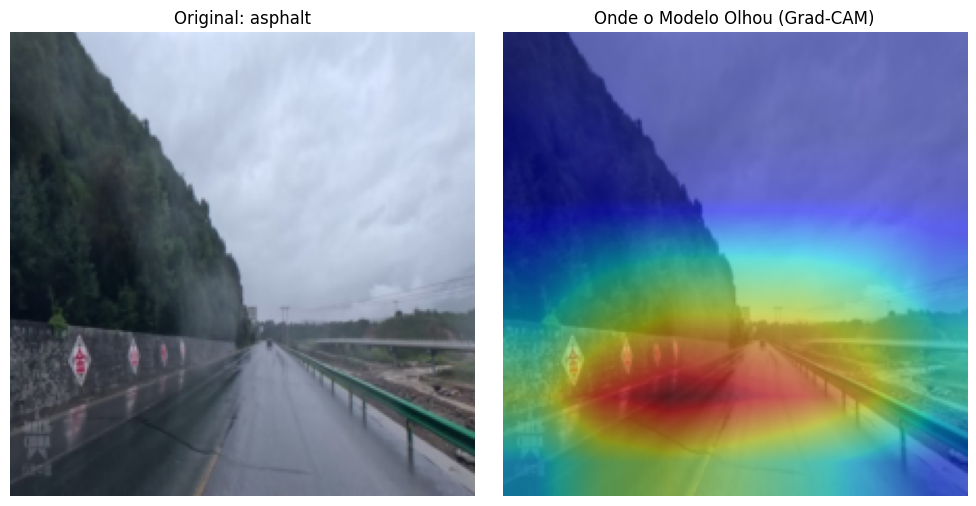

In [ ]:
import cv2
def gerar_gradcam(model, image_tensor, label):
    model.eval()

    mapas_ativacao = []
    gradientes = []

    def captura_forward(module, input, output):
        mapas_ativacao.append(output)

    def captura_backward(module, grad_input, grad_output):
        gradientes.append(grad_output[0])

    #Registra as capturas na última camada convolucional (layer4)
    handle_fwd = model.layer4.register_forward_hook(captura_forward)
    handle_bwd = model.layer4.register_full_backward_hook(captura_backward)

    #Passagem direta
    saida = model(image_tensor.unsqueeze(0).to(dispositivo))

    #Calcula o gradiente em relação à classe alvo
    model.zero_grad()
    perda_classe = saida[0, label]
    perda_classe.backward()

    #Remove as capturas após o uso
    handle_fwd.remove()
    handle_bwd.remove()

    #Média global dos gradientes por canal
    grads = gradientes[0].squeeze(0)
    pesos = grads.mean(dim=(1, 2))
    fmaps = mapas_ativacao[0].squeeze(0)

    #Ponderação dos mapas de ativação
    cam = torch.sum(pesos[:, None, None] * fmaps, dim=0)
    cam = cam.detach().cpu().numpy()

    #Mantém apenas ativações positivas
    cam = np.maximum(cam, 0)

    #Redimensiona para o tamanho da imagem original
    cam = cv2.resize(cam, (224, 224))

    #Normaliza entre 0 e 1
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    return cam


def plotar_gradcam(model, dataset, index):
    img_tensor, label = dataset[index]
    cam = gerar_gradcam(model, img_tensor, label)

    #Reverte a normalização
    img_show = img_tensor.permute(1, 2, 0).numpy()
    img_show = (img_show - img_show.min()) / (img_show.max() - img_show.min() + 1e-8)

    plt.figure(figsize=(10, 5))

    #Imagem original
    plt.subplot(1, 2, 1)
    plt.title(f"Original: {class_names[label]}")
    plt.imshow(img_show)
    plt.axis('off')

    #Imagem com mapa de calor sobreposto
    plt.subplot(1, 2, 2)
    plt.title("Onde o Modelo Olhou (Grad-CAM)")
    plt.imshow(img_show)
    plt.imshow(cam, cmap='jet', alpha=0.5)
    plt.axis('off')

    plt.tight_layout()
    plt.show()


print("Gerando visualização Grad-CAM")
plotar_gradcam(model_exp4, image_datasets['test'], index=58)

### **Ferramentas**

O uso de LLMs foi fundamental para fazer uma análise profunda dos resultados e gerar insights ao longo deste trabalho. A IA generativa não apenas acelerou o diagnóstico das métricas, como também permitiu uma interpretação mais estruturada dos padrões observados, sem comprometer o rigor analítico.



### **Conclusão**

A jornada do baseline à auditoria visual com Grad-CAM exigiu muito mais do que otimizar parâmetros: demandou uma análise rigorosa do processo como um todo e a maturidade para reconhecer quando o gargalo deixa de ser o código e passa a ser a qualidade dos dados no mundo real.